In [5]:
# pip install imagehash
import numpy as np, pandas as pd, imagehash
from PIL import Image
from tqdm.auto import tqdm
from pathlib import Path
import os
import random
import subprocess
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import ImageFile
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
import hashlib, numpy as np, pandas as pd, imagehash
from PIL import Image
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm

DATASET_HANDLE = "nocturnalnerd/balanced-dataset-701020"

def resolve_dataset_root() -> Path:
    explicit_root = os.environ.get("DATASET_ROOT")
    if explicit_root:
        explicit_path = Path(explicit_root)
        if explicit_path.exists():
            return explicit_path
        raise FileNotFoundError(f"DATASET_ROOT={explicit_path} does not exist.")
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    downloaded_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
    direct = downloaded_root / "dataset_result_70_10_20_balanced"
    if direct.exists():
        return direct
    discovered = [p for p in downloaded_root.rglob("dataset_result_70_10_20_balanced") if p.is_dir()]
    if len(discovered) == 1:
        return discovered[0]
    if all((downloaded_root / split).is_dir() for split in ("train", "validation", "test")):
        return downloaded_root
    raise FileNotFoundError(f"Could not locate dataset_result_balanced under {downloaded_root}.")

DATASET_ROOT = resolve_dataset_root()

m = pd.read_csv(DATASET_ROOT / "manifest.csv")

# # (a) Per-generator counts per split  -> goes into Table 4
# print(pd.crosstab(m.source_model, [m.split, m.label]))

# # (b) Shared prompts: Defactify images from the same caption share shard+row ID
# dif = m[m.source_dataset == "diffusion_defactify"].copy()
# dif["caption_key"] = dif.relative_path.str.extract(r"_((?:train|validation|test)-\d+-of-\d+_\d+)_")[0]
# print("captions in >1 split:", (dif.groupby("caption_key").split.nunique() > 1).sum())

# # (c) Near-duplicate images (perceptual hash)
# m["phash"] = [int(str(imagehash.phash(Image.open(DATASET_ROOT / p).convert("RGB"))), 16)
#               for p in tqdm(m.relative_path)]
# h = np.array(m.phash.tolist(), dtype=np.uint64)
# train_h = h[(m.split == "train").to_numpy()]
# other = np.where(m.split != "train")[0]
# m.loc[other, "min_dist"] = [np.unpackbits((train_h ^ h[i]).view(np.uint8)).reshape(-1, 64).sum(1).min()
#                             for i in tqdm(other)]
# print("exact (0):", (m.min_dist == 0).groupby(m.split).sum())
# print("near (<=4):", (m.min_dist <= 4).groupby(m.split).sum())

def ph(p):
    return str(imagehash.phash(Image.open(DATASET_ROOT / p).convert("RGB")))

with ProcessPoolExecutor(4) as ex:
    m["phash"] = list(tqdm(ex.map(ph, m.relative_path, chunksize=64), total=len(m)))
m.to_csv("/kaggle/working/manifest_with_phash.csv", index=False)   # never recompute again

# 1) Exact-hash pairs: which source/label in val/test matches which source/label in train?
tr  = m[m.split == "train"][["phash", "source_model", "label", "relative_path"]]
oth = m[m.split != "train"][["phash", "split", "source_model", "label", "relative_path"]]
pairs = oth.merge(tr, on="phash", suffixes=("", "_train")).drop_duplicates("relative_path")
print(pairs.groupby(["split", "source_model", "label", "source_model_train", "label_train"])
           .size().sort_values(ascending=False).head(30).to_string())

# 2) Are they truly identical? Check a sample at pixel level
def px(p):
    return hashlib.md5(np.asarray(Image.open(DATASET_ROOT / p).convert("RGB")).tobytes()).hexdigest()
s = pairs.sample(min(300, len(pairs)), random_state=0).copy()
s["identical"] = [px(a) == px(b) for a, b in zip(s.relative_path, s.relative_path_train)]
print(s.groupby(["source_model", "label"]).identical.agg(["mean", "size"]))

pairs.to_csv("/kaggle/working/dup_pairs.csv", index=False)

  0%|          | 0/55338 [00:00<?, ?it/s]

split       source_model  label  source_model_train  label_train
test        real          real   real                real           1104
validation  real          real   real                real            501
test        midjourney6   fake   midjourney6         fake            165
            sdxl          fake   sdxl                fake            152
            dalle3        fake   dalle3              fake            149
            sd3           fake   sd3                 fake            138
            sd21          fake   sd21                fake            132
validation  sdxl          fake   sdxl                fake             80
            sd21          fake   sd21                fake             74
            sd3           fake   sd3                 fake             71
            dalle3        fake   dalle3              fake             66
            midjourney6   fake   midjourney6         fake             65
test        AttGAN        fake   AttGAN              fake  

Most common hashes:
 phash
9bdb9d610c9261f8    4
b087f1279758ab26    4
eec14138f0d9c3e6    4
c4911be60c6b93bd    4
f48570d7897216f1    4
f0ed465a447847c7    4
bf9e804161113fee    4
c9c976663f15262c    4 

Flagged val/test images (<=4): 3300
Pixel-identical pairs: 0 of 2731 



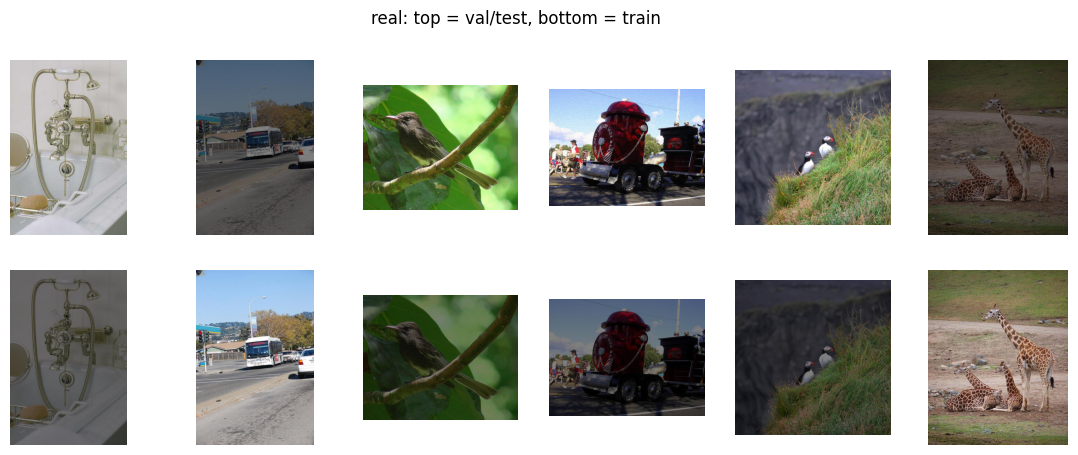

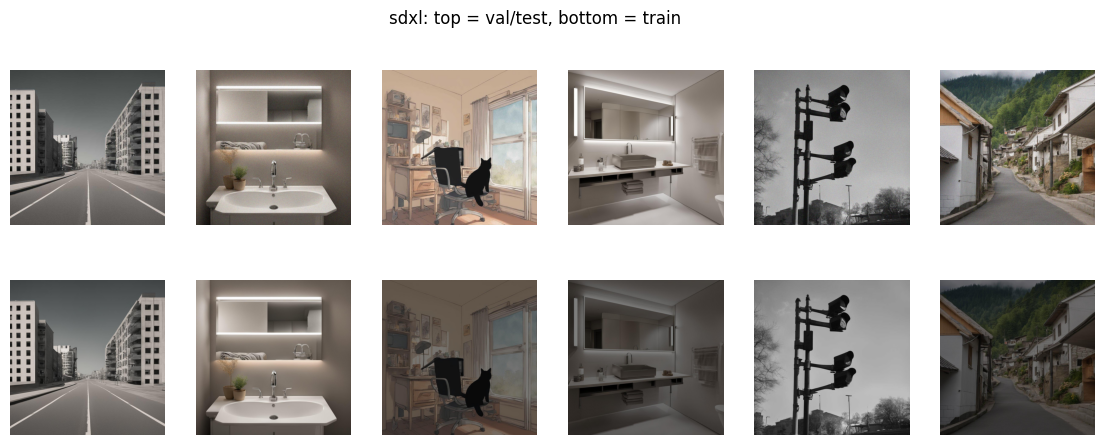

Removing 2248 of 11068 test images

alexnet_scratch      AUC all=0.9553  dedup=0.9476
dynamic_freqnet      AUC all=0.9958  dedup=0.9948
original_freqnet     AUC all=0.9843  dedup=0.9806
simple_cnn           AUC all=0.9538  dedup=0.9460

Dedup Dynamic - Original: +0.0142 [+0.0122, +0.0163]


In [6]:
import hashlib, numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image
from sklearn.metrics import roc_auc_score
import numpy as np, pandas as pd, imagehash
from PIL import Image
from tqdm.auto import tqdm
from pathlib import Path
import os
import random
import subprocess
import sys
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
from PIL import ImageFile
from sklearn.metrics import roc_auc_score
from torch.utils.data import DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder
import hashlib, numpy as np, pandas as pd, imagehash
from PIL import Image
from concurrent.futures import ProcessPoolExecutor
from tqdm.auto import tqdm

MANIFEST_PH = "/kaggle/input/datasets/mikekomari/rev2-6temporary/manifest_with_phash.csv"
PAIRS       = "/kaggle/input/datasets/mikekomari/rev2-6temporary/dup_pairs.csv"
PREDS       = "/kaggle/input/datasets/mikekomari/fulldatanewnew/full_predictions_long.csv"   # must contain dynamic_freqnet
# DATASET_ROOT: reuse resolve_dataset_root() from your other notebooks
DATASET_HANDLE = "nocturnalnerd/balanced-dataset-701020"

def resolve_dataset_root() -> Path:
    explicit_root = os.environ.get("DATASET_ROOT")
    if explicit_root:
        explicit_path = Path(explicit_root)
        if explicit_path.exists():
            return explicit_path
        raise FileNotFoundError(f"DATASET_ROOT={explicit_path} does not exist.")
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    downloaded_root = Path(kagglehub.dataset_download(DATASET_HANDLE))
    direct = downloaded_root / "dataset_result_70_10_20_balanced"
    if direct.exists():
        return direct
    discovered = [p for p in downloaded_root.rglob("dataset_result_70_10_20_balanced") if p.is_dir()]
    if len(discovered) == 1:
        return discovered[0]
    if all((downloaded_root / split).is_dir() for split in ("train", "validation", "test")):
        return downloaded_root
    raise FileNotFoundError(f"Could not locate dataset_result_balanced under {downloaded_root}.")
DATASET_ROOT = resolve_dataset_root()
m = pd.read_csv(MANIFEST_PH)
pairs = pd.read_csv(PAIRS)

# ---- A. Is the hash degenerate? (one value shared by hundreds of images = hash artefact)
print("Most common hashes:\n", m.phash.value_counts().head(8).to_string(), "\n")

# ---- B. Near-duplicates (Hamming <= 4) for every val/test image, fast
h = np.array([int(x, 16) for x in m.phash], dtype=np.uint64)
is_tr = (m.split == "train").to_numpy()
tr, idx = h[is_tr], np.where(~is_tr)[0]
md = np.array([np.bitwise_count(tr ^ h[i]).min() for i in idx])
flag = set(m.loc[idx[md <= 4], "relative_path"])
print("Flagged val/test images (<=4):", len(flag))

# ---- C. Pixel-identical check on ALL exact-hash pairs
def px(p): return hashlib.md5(np.asarray(Image.open(DATASET_ROOT / p).convert("RGB")).tobytes()).hexdigest()
pairs["identical"] = [px(a) == px(b) for a, b in zip(pairs.relative_path, pairs.relative_path_train)]
print("Pixel-identical pairs:", int(pairs.identical.sum()), "of", len(pairs), "\n")

# ---- D. Look at 6 pairs each (top = test/val, bottom = train)
for src in ["real", "sdxl"]:
    s = pairs[pairs.source_model == src].sample(6, random_state=0)
    fig, ax = plt.subplots(2, 6, figsize=(14, 5))
    for j, (a, b) in enumerate(zip(s.relative_path, s.relative_path_train)):
        ax[0, j].imshow(Image.open(DATASET_ROOT / a)); ax[1, j].imshow(Image.open(DATASET_ROOT / b))
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle(f"{src}: top = val/test, bottom = train"); plt.show()

# ---- E. Robustness: metrics with flagged test images removed
pred = pd.read_csv(PREDS)
pred = pred[pred.relative_path.str.startswith("test/")]
pred["dup"] = pred.relative_path.isin(flag)
print(f"Removing {pred[pred.model == pred.model.iloc[0]].dup.sum()} of "
      f"{(pred.model == pred.model.iloc[0]).sum()} test images\n")
for name, g in pred.groupby("model"):
    c = g[~g.dup]
    print(f"{name:20s} AUC all={roc_auc_score(g.y_true, g.y_prob):.4f}  "
          f"dedup={roc_auc_score(c.y_true, c.y_prob):.4f}")

# Paired bootstrap Dynamic - Original on the deduplicated test set
w = pred[~pred.dup].pivot(index="relative_path", columns="model", values="y_prob")
y = pred[~pred.dup].drop_duplicates("relative_path").set_index("relative_path").y_true.loc[w.index].to_numpy()
rng, d = np.random.default_rng(42), []
for _ in range(1000):
    i = rng.integers(0, len(y), len(y))
    if len(np.unique(y[i])) < 2: continue
    d.append(roc_auc_score(y[i], w.dynamic_freqnet.values[i]) - roc_auc_score(y[i], w.original_freqnet.values[i]))
delta = roc_auc_score(y, w.dynamic_freqnet) - roc_auc_score(y, w.original_freqnet)
print(f"\nDedup Dynamic - Original: {delta:+.4f} [{np.percentile(d, 2.5):+.4f}, {np.percentile(d, 97.5):+.4f}]")